In [2]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Extinction_changes')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *


os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Permittivity changes estimation')
from Permittivity_change_func import *
import Permittivity_change_func
importlib.reload(Permittivity_change_func)
from Permittivity_change_func  import *


os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Optical detection\Extinction_changes')
from Optical_amplitude_estimation_func import *
import Optical_amplitude_estimation_func
importlib.reload(Optical_amplitude_estimation_func)
from Optical_amplitude_estimation_func  import *



from matplotlib.widgets import Slider, Button


In [3]:


Permittivity_change = {}

Energy = np.linspace(1.1, 3.9, 1000)
alpha = 1.42e-5 #in K-1

#Gold values from Stoll 2014
w_p = 9.01 * sc.constants.e / sc.constants.hbar
gamma_0 = 67*1e-3 * sc.constants.e / sc.constants.hbar
dgamma_dT = 0.125e-3 * sc.constants.e / sc.constants.hbar #eV/K e-ph scattering change 

Interband contribution

In [4]:
# My detailed fit close to Stoll 2014
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Interband sensitivity model\Computed interband changes'
fname = 'Interband contribution - Stoll fit - with Stoll coefficients.csv'
Permittivity_change['ib'] = get_treated_interband_contribution(dir_root, fname)

# Raw data from stoll 2014
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Acoustic model - data'
Permittivity_change['Stoll ib'] = get_interband_contribution_Stoll_2014(dir_root)

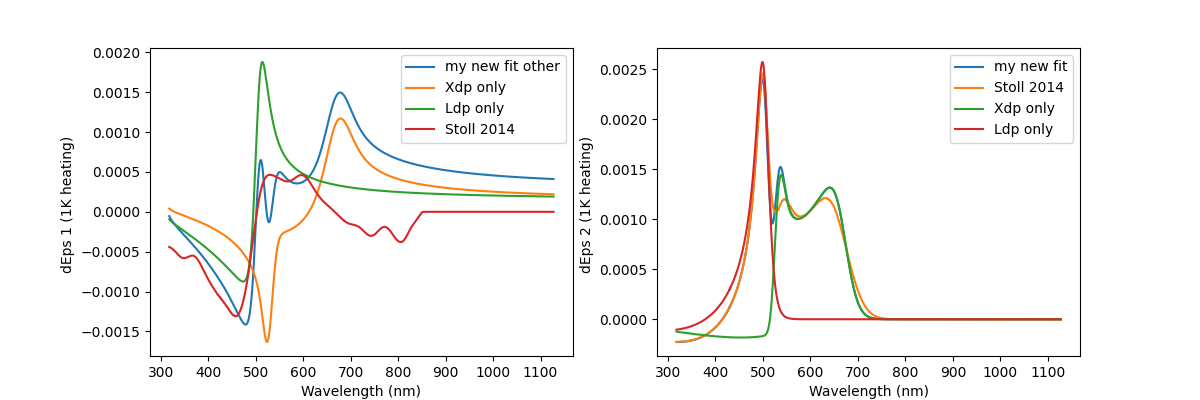

In [15]:
fig, ax = plt.subplots(figsize=(12,4), ncols=2)

ax[0].plot(1240/Energy, -Permittivity_change['ib']['deps1/deV']['Ldp'](Energy) *(-1.7e-4) - Permittivity_change['ib']['deps1/deV']['Xdp'](Energy) *(-3.2e-4), label = 'my new fit other')
ax[0].plot(1240/Energy, -Permittivity_change['ib']['deps1/deV']['Ldp'](Energy) *(0) - Permittivity_change['ib']['deps1/deV']['Xdp'](Energy) *(-3.2e-4), label = 'Xdp only')

ax[0].plot(1240/Energy, -Permittivity_change['ib']['deps1/deV']['Ldp'](Energy) *(-1.7e-4) - Permittivity_change['ib']['deps1/deV']['Xdp'](Energy) *(0), label = 'Ldp only')
ax[0].plot(1240/Energy, Permittivity_change['Stoll ib']['delta_eps1']['total'](Energy), label = 'Stoll 2014')

ax[0].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('dEps 1 (1K heating) ')
ax[0].legend()
ax[1].plot(1240/Energy, Permittivity_change['ib']['delta_eps2']['total'](Energy)*3*alpha, label = 'my new fit')
ax[1].plot(1240/Energy, Permittivity_change['Stoll ib']['delta_eps2']['total'](Energy), label = 'Stoll 2014')

ax[1].plot(1240/Energy, -Permittivity_change['ib']['deps2/deV']['Ldp'](Energy) *(0) - Permittivity_change['ib']['deps2/deV']['Xdp'](Energy) *(-3.2e-4), label = 'Xdp only')

ax[1].plot(1240/Energy, -Permittivity_change['ib']['deps2/deV']['Ldp'](Energy) *(-1.7e-4) - Permittivity_change['ib']['deps2/deV']['Xdp'](Energy) *(0), label = 'Ldp only')
ax[1].set_xlabel('Wavelength (nm)')
ax[1].set_ylabel('dEps 2 (1K heating) ')

plt.legend()

Electron density contribution

In [6]:
delta_eps1_func, delta_eps2_func = Delta_eps_e_density(w_p = w_p, gamma_0 = gamma_0)
Permittivity_change['Drude'] = {}
Permittivity_change['Drude']['e density'] = {}
Permittivity_change['Drude']['e density']['delta_eps1'] = delta_eps1_func
Permittivity_change['Drude']['e density']['delta_eps2'] = delta_eps2_func

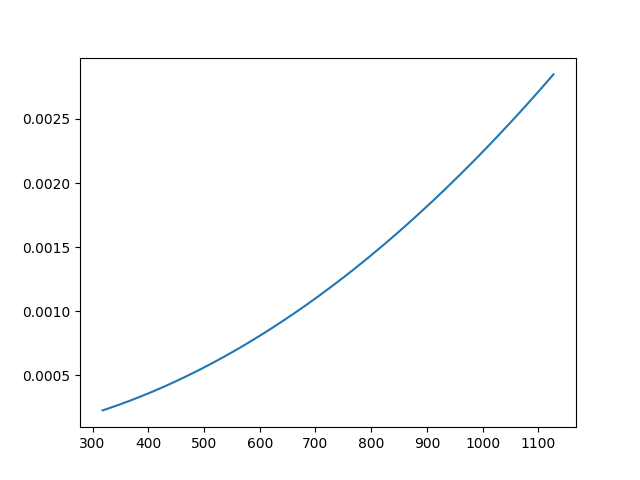

In [7]:
fig, ax = plt.subplots()

ax.plot(1240/Energy, Permittivity_change['Drude']['e density']['delta_eps1'](Energy)*3*alpha)


e-ph scattering contribution

In [8]:
deps1_dT_scattering, deps2_dT_scattering = Delta_eps_e_ph_scattering(w_p, gamma_0, dgamma_dT)

Permittivity_change['Drude']['e-ph scattering'] = {}
Permittivity_change['Drude']['e-ph scattering']['delta_eps1'] = deps1_dT_scattering
Permittivity_change['Drude']['e-ph scattering']['delta_eps2'] = deps2_dT_scattering

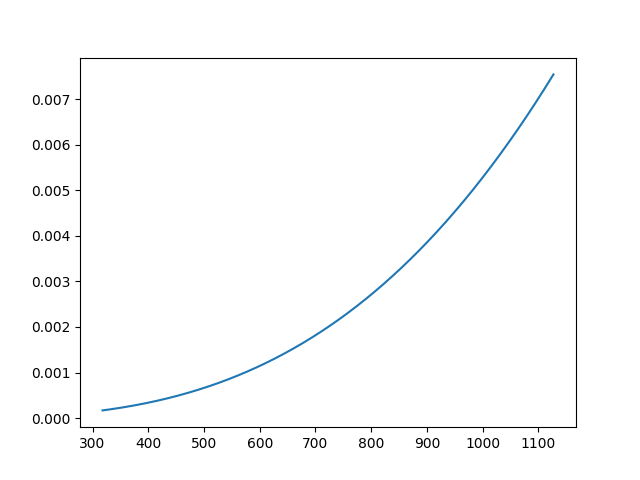

In [9]:
fig, ax = plt.subplots()

ax.plot(1240/Energy, Permittivity_change['Drude']['e-ph scattering']['delta_eps2'](Energy))

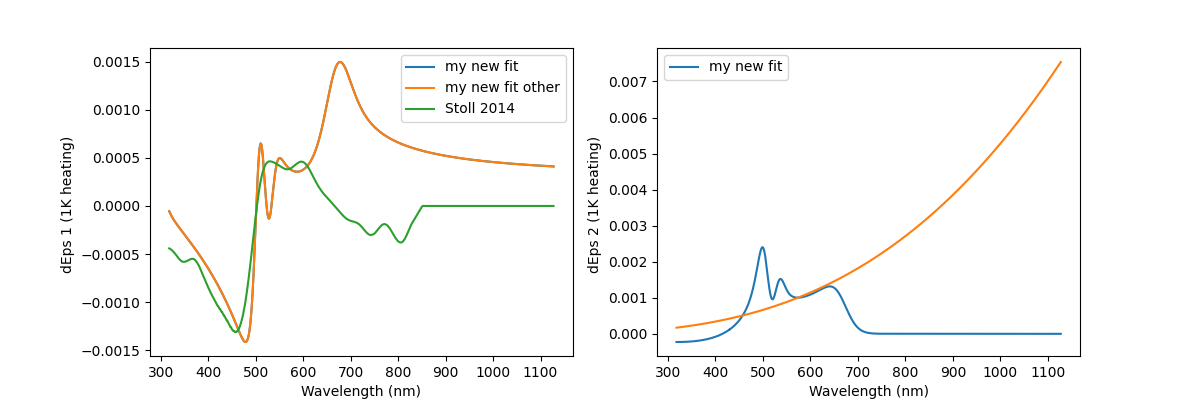

In [10]:
fig, ax = plt.subplots(figsize=(12,4), ncols=2)

ax[0].plot(1240/Energy, Permittivity_change['ib']['delta_eps1']['total'](Energy)*3*alpha, label = 'my new fit')
ax[0].plot(1240/Energy, -Permittivity_change['ib']['deps1/deV']['Ldp'](Energy) *(-1.7e-4) - Permittivity_change['ib']['deps1/deV']['Xdp'](Energy) *(-3.2e-4), label = 'my new fit other')
ax[0].plot(1240/Energy, Permittivity_change['Stoll ib']['delta_eps1']['total'](Energy), label = 'Stoll 2014')
ax[0].set_xlabel('Wavelength (nm)')
ax[0].set_ylabel('dEps 1 (1K heating) ')
ax[0].legend()
ax[1].plot(1240/Energy, Permittivity_change['ib']['delta_eps2']['total'](Energy)*3*alpha, label = 'my new fit')
ax[1].plot(1240/Energy, Permittivity_change['Drude']['e-ph scattering']['delta_eps2'](Energy))
ax[1].set_xlabel('Wavelength (nm)')
ax[1].set_ylabel('dEps 2 (1K heating) ')

plt.legend()

## Get Sigma_Mie spectra

In [11]:
dir_root_data=r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations\a=50, c=10, gamma_corr=120meV'
Spectra_info = get_spectra_synthesis_ellipsoid(dir_root_data, fname = 'Synthesis.dat')

In [12]:
Ds_heating = compute_heating_changes(Permittivity_change, Spectra_info, band_contribution='Stoll', with_dilatation=True)
Ds_dilatation = compute_dilatation_changes(Permittivity_change, Spectra_info, band_contribution='Stoll')
Ds_contraction = compute_contraction_changes(Permittivity_change, Spectra_info, band_contribution='Stoll')

dir_to_save = dir_root_data + r'\\Extinction changes'
save_data = 0
if save_data :
    save_ext_change_data_excel('Extinction change - heating', dir_to_save, Ds_heating)
    save_ext_change_data_excel('Extinction change - dilatation', dir_to_save, Ds_dilatation)
    save_ext_change_data_excel('Extinction change - contraction', dir_to_save, Ds_contraction)

## Print results

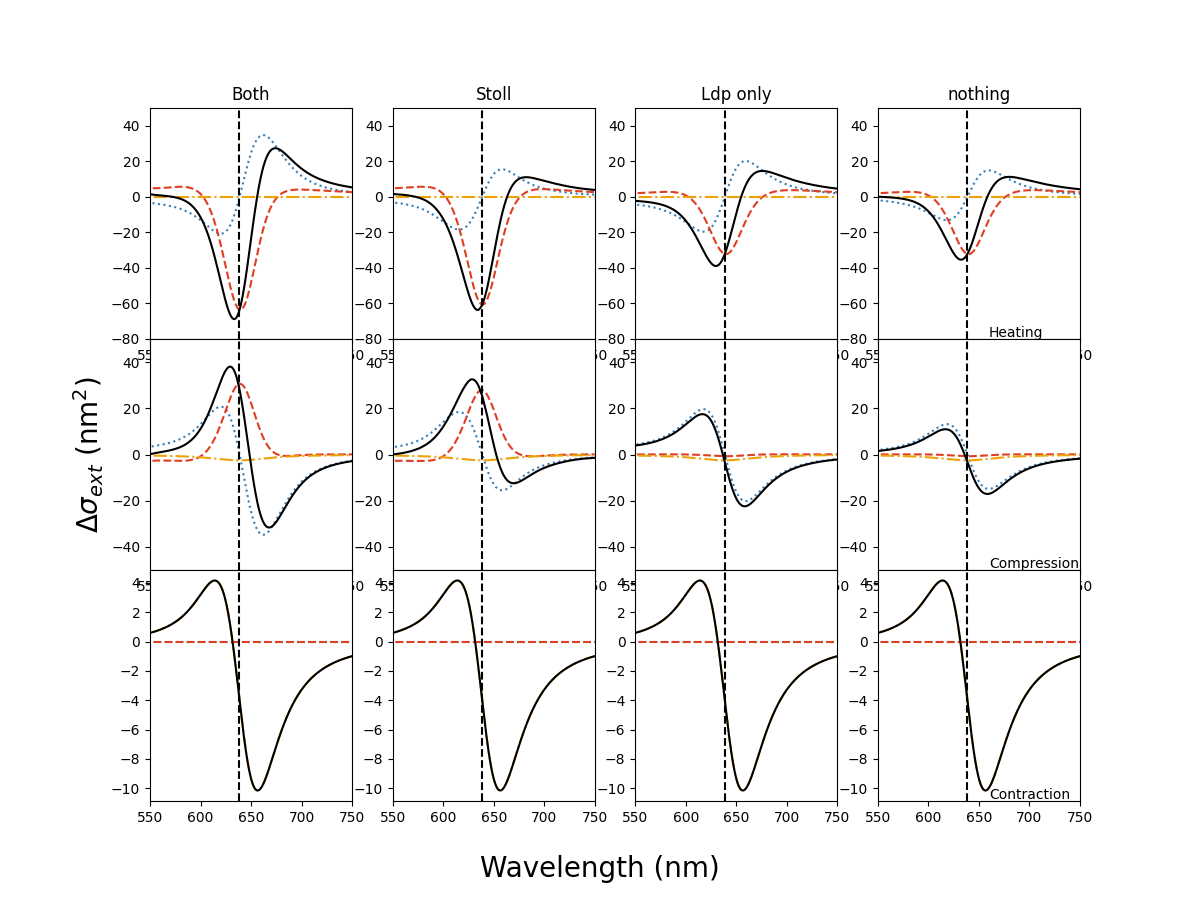

In [19]:
lda_SPR = 638.5
#lsa_SPR = 628

fig, ax = plt.subplots(nrows=3,  ncols= 4, figsize=(12, 9))

plot_3_modes(ax[:,0], Permittivity_change, Spectra_info, band_contribution = 'both', lda_SPR = lda_SPR)
ax[0, 0].set_title('Both')

plot_3_modes(ax[:,1], Permittivity_change, Spectra_info, band_contribution = 'Stoll', lda_SPR = lda_SPR)
ax[0, 1].set_title('Stoll')

plot_3_modes(ax[:,2], Permittivity_change, Spectra_info, band_contribution = 'Ldp', lda_SPR = lda_SPR)
ax[0, 2].set_title('Ldp only')


plot_3_modes(ax[:,3], Permittivity_change, Spectra_info, band_contribution = 'nothing', Xdp_coeff=-2e-4, lda_SPR = lda_SPR)
ax[0, 3].set_title('nothing')


for index in [(0, 0), (0, 1), (0, 2), (0, 3)] :
    ax[index].set_ylim((-80, 50))


for index in [(1, 0), (1, 1), (1, 2), (1, 3)] :
    ax[index].set_ylim((-50, 50))


for a in ax[0,:] :
    a.set_xlim((550, 750))

for a in ax[1,:] :
    a.set_xlim((550, 750))
for a in ax[2,:] :
    a.set_xlim((550, 750))

plt.subplots_adjust(hspace=0)


# for index in [(2, 0), (2, 1), (2, 2), (2, 3)] :
#     ax[index].set_xlabel('Wavelength (nm)', fontsize=20)


for index in [(1, 0), ] :
    ax[index].set_ylabel(r'$\Delta \sigma_{ext}$ (nm$^2$)', fontsize=20)

plt.suptitle('Wavelength (nm)', y=0.05, fontsize=20)
ax[1, 3].text(0.55, 0.01, 'Compression', fontsize=10 , transform=ax[1, 3].transAxes)
ax[0, 3].text(0.55, 0.01, 'Heating', fontsize=10 , transform=ax[0, 3].transAxes)
ax[2, 3].text(0.55, 0.01, 'Contraction', fontsize=10 , transform=ax[2, 3].transAxes)
dir_save_fig = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Optical study\Ellipsoid simulations'

os.chdir(dir_save_fig)

plt.savefig('Different interband model.png')